In [14]:
from keras.utils import to_categorical
from keras.preprocessing.image import load_img, img_to_array
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import os
import numpy as np
import pandas as pd
import tqdm


In [2]:
train_dir='images/train'
test_dir='images/test'

In [3]:
import os

def createdataframe(data_dir):
    images_path = []
    labels = []

    for label in os.listdir(data_dir):
        label_dir = os.path.join(data_dir, label)

        if not os.path.isdir(label_dir):
            continue

        for image_file in os.listdir(label_dir):
            image_path = os.path.join(label_dir, image_file)

            if os.path.isfile(image_path):
                images_path.append(image_path)
                labels.append(label)

        print("Labels completed:", label)

    return images_path, labels

In [5]:
images_path, labels = createdataframe(
    r"C:\Users\zaima\face_recognition\archive (3)\images\images\train"
)

Labels completed: angry
Labels completed: disgust
Labels completed: fear
Labels completed: happy


In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split

train_dir = r"C:\Users\zaima\face_recognition\archive (3)\images\images\train"

images_path, labels = createdataframe(train_dir)
data = pd.DataFrame({"images": images_path, "labels": labels})

train, test = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    stratify=data["labels"]
)

print("Training images:", len(train))
print("Test images:", len(test))

Labels completed: angry
Labels completed: disgust
Labels completed: fear
Labels completed: happy
Training images: 10780
Test images: 2695


In [18]:
from tqdm import tqdm

In [20]:
def extract_features(images):
    features=[]
    for image in tqdm(images):
        img=load_img(image,target_size=(48,48),color_mode='grayscale')
        img=np.array(img)
        features.append(img)
    features=np.array(features)
    features=features.reshape(features.shape[0],48,48,1)
    return features
        

In [21]:

train_features=extract_features(train["images"])

100%|██████████| 10780/10780 [03:13<00:00, 55.74it/s]


In [22]:
test_features=extract_features(test["images"])

100%|██████████| 2695/2695 [00:57<00:00, 47.08it/s]


In [23]:
X_train=train_features/255.0
X_test=test_features/255.0

In [25]:
from sklearn.preprocessing import LabelEncoder
label_enocoder=LabelEncoder()
label_enocoder.fit(train['labels'])

LabelEncoder()

In [26]:
y_train=label_enocoder.transform(train['labels'])
y_test=label_enocoder.transform(test['labels'])

In [27]:
y_train=to_categorical(y_train,num_classes=7)
y_test=to_categorical(y_test,num_classes=7)

In [31]:
model=Sequential()
model.add(Conv2D(32,kernel_size=(3,3),activation='relu',input_shape=(48,48,1)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(64,kernel_size=(3,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(128,kernel_size=(3,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128,activation='relu'))
model.add(Dense(7,activation='softmax'))
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)


c:\Users\zaima\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
history = model.fit(
    x=X_train,
    y=y_train,
    batch_size=128,
    epochs=10,
    validation_data=(X_test, y_test)
)

Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 13s 99ms/step - accuracy: 0.3514 - loss: 1.2484 - val_accuracy: 0.4416 - val_loss: 1.1788
Epoch 2/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.4427 - loss: 1.1544 - val_accuracy: 0.5006 - val_loss: 1.0911
Epoch 3/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.5440 - loss: 1.0391 - val_accuracy: 0.5896 - val_loss: 0.9580
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 12s 143ms/step - accuracy: 0.5923 - loss: 0.9528 - val_accuracy: 0.6286 - val_loss: 0.8799
Epoch 5/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 13s 146ms/step - accuracy: 0.6275 - loss: 0.8806 - val_accuracy: 0.6271 - val_loss: 0.8591
Epoch 6/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.6545 - loss: 0.8342 - val_accuracy: 0.6571 - val_loss: 0.8161
Epoch 7/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 10s 113ms/step - accuracy: 0.6701 - loss: 0.7961 - val_accuracy: 0.6568 - val_loss: 0.8130
Epoch 8/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 98ms/step - accuracy: 0.6853 - loss: 0.7596 - val_accuracy:

In [35]:
model_json=model.to_json()
with open("model.json", "w") as json_file:
    json_file.write(model_json)
    model.save("emotional_detector.h5")

In [55]:
image_path = r"C:\Users\zaima\face_recognition\archive (3)\images\images\train\angry/134.jpg"

image = load_img(image_path, target_size=(48, 48), color_mode="grayscale")
image_array = img_to_array(image).astype("float32") / 255.0
image_array = np.expand_dims(image_array, axis=0)

probabilities = model.predict(image_array, verbose=0)[0]
predicted_label = class_names[np.argmax(probabilities)]

print(f"Prediction: {predicted_label}")
print(f"Confidence: {np.max(probabilities):.2%}")

Prediction: angry
Confidence: 68.60%


In [39]:
%pip install matplotlib


Note: you may need to restart the kernel to use updated packages.


Text(0.5, 1.0, 'Prediction: angry\nConfidence: 68.60%')

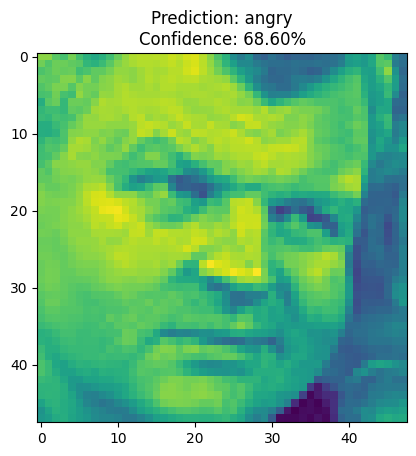

In [56]:
import matplotlib.pyplot as plt
plt.imshow(image_array[0].reshape(48, 48))
plt.title(f"Prediction: {predicted_label}\nConfidence: {np.max(probabilities):.2%}")

